# **Nama: Andika Dinata**
# **NIM: 123140096**

In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy.stats import chisquare
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# Soal 1: Data Sintetis dan Baseline Unimodal

## a. Bangkitkan data sintetis dengan dua faktor laten biner (valensi dari wajah, gairah dari suara). Label adalah gabungan keduanya sehingga menghasilkan empat kelas.

In [46]:
rng = np.random.default_rng(42)
n = 4000

# two binary latent factors: valence (visual) and arousal (audio)
z_visual = rng.integers(0, 2, size=n)    # half of the answer
z_audio = rng.integers(0, 2, size=n)     # half of the answer

# 16 features per modality, everything starts as Gaussian noise
visual = rng.normal(0, 1.0, size=(n, 16)).astype(np.float32)
audio = rng.normal(0, 1.0, size=(n, 16)).astype(np.float32)

# dimension 0 carries the latent factor (-1 or +1), the rest stays uninformative noise
visual[:, 0] = z_visual * 2.0 - 1.0
audio[:, 0] = z_audio * 2.0 - 1.0

# the label combines both factors, so there are 4 classes
label = z_visual * 2 + z_audio

print("visual:", visual.shape, "| audio:", audio.shape)
print("class distribution:", np.bincount(label))

visual: (4000, 16) | audio: (4000, 16)
class distribution: [1033  973 1024  970]


## b. Tampilkan distribusi kelas pada data. Pastikan keempat kelas berimbang.

,count,percent
"Class 0 (V0, A0)",1033,25.82
"Class 1 (V0, A1)",973,24.32
"Class 2 (V1, A0)",1024,25.60
"Class 3 (V1, A1)",970,24.25


Largest gap from 25%: 0.82 percentage points
Chi-square test: chi2 = 3.29, p = 0.348


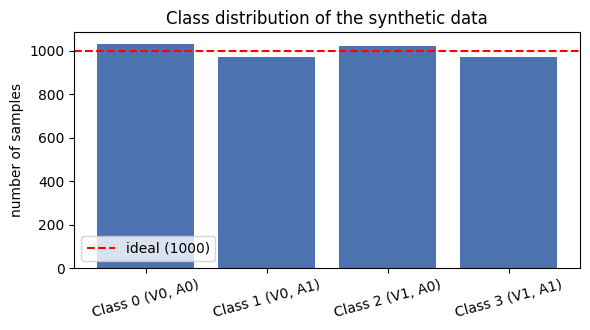

In [47]:
counts = np.bincount(label)
# V = valence (from the face), A = arousal (from the voice)
class_names = ["Class 0 (V0, A0)", "Class 1 (V0, A1)", "Class 2 (V1, A0)", "Class 3 (V1, A1)"]

class_table = pd.DataFrame({
    "count": counts,
    "percent": (counts / n * 100).round(2),
}, index=class_names)
display(class_table)

chi2, p_value = chisquare(counts)
print(f"Largest gap from 25%: {np.abs(counts / n * 100 - 25).max():.2f} percentage points")
print(f"Chi-square test: chi2 = {chi2:.2f}, p = {p_value:.3f}")

plt.figure(figsize=(6, 3.4))
plt.bar(class_names, counts, color="#4C72B0")
plt.axhline(n / 4, color="red", linestyle="--", label="ideal (1000)")
plt.ylabel("number of samples")
plt.title("Class distribution of the synthetic data")
plt.xticks(rotation=15)
plt.legend()
plt.tight_layout()
plt.show()

## c. Latih dua model unimodal terpisah: satu hanya menerima fitur visual, satu hanya menerima fitur audio. Laporkan akurasi masing-masing di data uji.

In [48]:
def build_encoder(fan_in=16, fan_out=32, seed=0):
    """FROZEN encoder with tanh activation.
    Note: use tanh, not ReLU. ReLU can kill the dimensions that carry the
    latent factor, so the information is lost before it can be fused."""
    g = torch.Generator().manual_seed(seed)
    enc = nn.Sequential(
        nn.Linear(fan_in, fan_out), nn.Tanh(),
        nn.Linear(fan_out, fan_out), nn.Tanh(),
    )
    with torch.no_grad():                    # controlled initialization
        for p in enc.parameters():
            if p.dim() > 1:
                p.copy_(torch.randn(p.shape, generator=g) / p.shape[1] ** 0.5)
            else:
                p.zero_()
    enc.eval()
    for p in enc.parameters():               # freeze
        p.requires_grad_(False)
    return enc

ENC_VISUAL = build_encoder(seed=1)
ENC_AUDIO = build_encoder(seed=2)
print("visual encoder parameters:", sum(p.numel() for p in ENC_VISUAL.parameters()))
print("audio encoder parameters :", sum(p.numel() for p in ENC_AUDIO.parameters()))
still_trainable = any(p.requires_grad for p in list(ENC_VISUAL.parameters()) + list(ENC_AUDIO.parameters()))
print("any encoder parameter still trainable?", still_trainable)

visual encoder parameters: 1600
audio encoder parameters : 1600
any encoder parameter still trainable? False


Selanjutnya data dibagi menjadi data latih dan data uji

In [49]:
# Data split: 80% train, 20% test, class proportions kept equal (stratified)
idx_train, idx_test = train_test_split(np.arange(n), test_size=0.2, stratify=label, random_state=42)

# convert to tensors so they can go straight into the models
v_tr, v_te = torch.tensor(visual[idx_train]), torch.tensor(visual[idx_test])
a_tr, a_te = torch.tensor(audio[idx_train]), torch.tensor(audio[idx_test])
y_tr, y_te = torch.tensor(label[idx_train]), torch.tensor(label[idx_test])
print("train samples:", len(y_tr), "| test samples:", len(y_te))
print("test class distribution:", np.bincount(y_te.numpy()))


def train(model, inputs, y, epochs=300, lr=0.01):
    """Train with Adam + cross-entropy (full batch). inputs = tuple of model inputs.
    Only parameters with requires_grad=True are updated, so the frozen encoders stay safe."""
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    for _ in range(epochs):
        opt.zero_grad()
        loss_fn(model(*inputs), y).backward()
        opt.step()
    model.eval()


def evaluate(model, visual, audio, label):
    """Accuracy of a fusion model on the given data."""
    with torch.no_grad():
        pred = model(visual, audio).argmax(dim=1)
    return (pred == label).float().mean().item()

train samples: 3200 | test samples: 800
test class distribution: [207 194 205 194]


Sekarang dua model unimodal: satu hanya menerima fitur visual, satu hanya menerima fitur audio. Fitur dari encoder beku cukup dihitung sekali karena encoder tidak berubah, lalu masing-masing diberi satu lapisan linear sebagai kepala.

In [50]:
# the frozen encoders only run forward (no gradients), so the features can be computed once
with torch.no_grad():
    f_v_tr, f_v_te = ENC_VISUAL(v_tr), ENC_VISUAL(v_te)
    f_a_tr, f_a_te = ENC_AUDIO(a_tr), ENC_AUDIO(a_te)

# unimodal models: one linear layer on top of each modality's encoder features
torch.manual_seed(42)
uni_visual = nn.Linear(32, 4)
train(uni_visual, (f_v_tr,), y_tr)

torch.manual_seed(42)
uni_audio = nn.Linear(32, 4)
train(uni_audio, (f_a_tr,), y_tr)

acc_uni_v = (uni_visual(f_v_te).argmax(1) == y_te).float().mean().item()
acc_uni_a = (uni_audio(f_a_te).argmax(1) == y_te).float().mean().item()
print(f"Visual-only accuracy: {acc_uni_v:.4f}")
print(f"Audio-only accuracy : {acc_uni_a:.4f}")

Visual-only accuracy: 0.4963
Audio-only accuracy : 0.5138


## d. Jawab dalam 3-5 kalimat: mengapa akurasi kedua model unimodal berhenti di sekitar 50% dan tidak dapat melampauinya?

Akurasi visual-only (0,4963) dan audio-only (0,5138) sama-sama mendekati 50% karena setiap modalitas hanya membawa satu dari dua faktor laten: visual hanya memuat valensi, audio hanya memuat gairah. Dari satu modalitas, model hanya bisa mempersempit empat kelas menjadi dua kandidat, lalu menebak salah satunya, jadi peluang benarnya sekitar 50%. Informasi faktor yang satunya tidak ada di input, sehingga model sebaik apa pun tidak bisa melampaui angka itu.

# Soal 2: Early Fusion

## a. Bentuk vektor gabungan z = [ fA(xA); fB (xB ) ] dari keluaran kedua encoder beku.

In [51]:
z = torch.cat([f_v_te, f_a_te], dim=1)
print("f_visual:", tuple(f_v_te.shape), "| f_audio:", tuple(f_a_te.shape), "| combined z:", tuple(z.shape))

f_visual: (800, 32) | f_audio: (800, 32) | combined z: (800, 64)


## b. Latih satu model bersama (MLP) di atas z, lalu laporkan akurasinya.

In [52]:
class EarlyFusion(nn.Module):
    """Concatenate the encoder features, then use one shared model."""
    def __init__(self, dim_enc=32, n_classes=4):
        super().__init__()
        self.head = nn.Sequential(
            nn.Linear(dim_enc * 2, 64), nn.Tanh(),
            nn.Linear(64, n_classes),
        )

    def forward(self, x_visual, x_audio):
        with torch.no_grad():                     # frozen encoders
            f_a = ENC_VISUAL(x_visual)
            f_b = ENC_AUDIO(x_audio)
        z = torch.cat([f_a, f_b], dim=1)          # concatenation at the earliest layer
        return self.head(z)

torch.manual_seed(42)
m_early = EarlyFusion()
train(m_early, (v_tr, a_tr), y_tr)
acc_early = evaluate(m_early, v_te, a_te, y_te)
print(f"Early Fusion accuracy: {acc_early:.4f}")
print(f"(train accuracy: {evaluate(m_early, v_tr, a_tr, y_tr):.4f})")

Early Fusion accuracy: 0.9613
(train accuracy: 1.0000)


## c. Bandingkan dengan baseline unimodal Soal 1. Apakah fusi menambah nilai?

In [53]:
early_compare = pd.DataFrame({
    "test accuracy": [acc_uni_v, acc_uni_a, acc_early],
    "gain over best unimodal": [np.nan, np.nan, acc_early - max(acc_uni_v, acc_uni_a)],
}, index=["Visual only", "Audio only", "Early Fusion"]).round(4)
display(early_compare)

,test accuracy,gain over best unimodal
Visual only,0.4963,NaN
Audio only,0.5138,NaN
Early Fusion,0.9613,0.4475


Ya, fusi sangat menambah nilai. Early Fusion mencapai 0,961 di data uji, sedangkan unimodal terbaik hanya 0,514, jadi naik sekitar 45 persen.

Ini terjadi karena vektor gabungan `z` memuat kedua faktor laten sekaligus (valensi dari visual, gairah dari audio), sehingga MLP bersama bisa menentukan satu dari empat kelas. Akurasinya belum 100% padahal akurasi latihnya 1,000, kemungkinan karena model ikut menghafal suara berisik pada data latih.

# Soal 3: Late Fusion

## a. Latih dua model unimodal terpisah di atas fitur encoder, masing-masing menghasilkan skor keyakinan untuk keempat kelas.

In [54]:
class LateFusion(nn.Module):
    """Two unimodal heads; the decisions are combined at the end."""
    def __init__(self, dim_enc=32, n_classes=4):
        super().__init__()
        self.head_a = nn.Sequential(nn.Linear(dim_enc, n_classes))
        self.head_b = nn.Sequential(nn.Linear(dim_enc, n_classes))
        self.w_a = nn.Parameter(torch.tensor(0.5))   # modality weights
        self.w_b = nn.Parameter(torch.tensor(0.5))

    def forward(self, x_visual, x_audio):
        with torch.no_grad():
            f_a = ENC_VISUAL(x_visual)
            f_b = ENC_AUDIO(x_audio)
        p_a = torch.softmax(self.head_a(f_a), dim=1)
        p_b = torch.softmax(self.head_b(f_b), dim=1)
        return self.w_a * p_a + self.w_b * p_b       # decision-level fusion

# train the two heads separately, each one only sees the features of its own modality
# (w_a and w_b are not trained, they stay 0.5 and 0.5, i.e. a plain average)
torch.manual_seed(42)
m_late = LateFusion()
train(m_late.head_a, (f_v_tr,), y_tr)
train(m_late.head_b, (f_a_tr,), y_tr)

# accuracy of each head on its own
acc_head_a = (m_late.head_a(f_v_te).argmax(1) == y_te).float().mean().item()
acc_head_b = (m_late.head_b(f_a_te).argmax(1) == y_te).float().mean().item()
print(f"Visual head only: {acc_head_a:.4f}")
print(f"Audio head only : {acc_head_b:.4f}")

Visual head only: 0.4963
Audio head only : 0.5188


## b. Gabungkan kedua skor dengan rata-rata terbobot, lalu laporkan akurasinya.

In [55]:
acc_late = evaluate(m_late, v_te, a_te, y_te)
print(f"Late Fusion accuracy (w_a = w_b = 0.5): {acc_late:.4f}")

# one example sample: see how the two scores complement each other
i = 0
with torch.no_grad():
    p_a = torch.softmax(m_late.head_a(f_v_te[i:i+1]), dim=1)[0]
    p_b = torch.softmax(m_late.head_b(f_a_te[i:i+1]), dim=1)[0]
example = pd.DataFrame({"p_visual": p_a.numpy(), "p_audio": p_b.numpy(),
                        "combined (0.5/0.5)": (0.5 * p_a + 0.5 * p_b).numpy()},
                       index=["class 0", "class 1", "class 2", "class 3"]).round(3)
print("True label of this sample: class", y_te[i].item())
display(example)

Late Fusion accuracy (w_a = w_b = 0.5): 0.9550
True label of this sample: class 2


,p_visual,p_audio,combined (0.5/0.5)
class 0,0.052,0.416,0.234
class 1,0.040,0.101,0.071
class 2,0.486,0.407,0.446
class 3,0.422,0.076,0.249


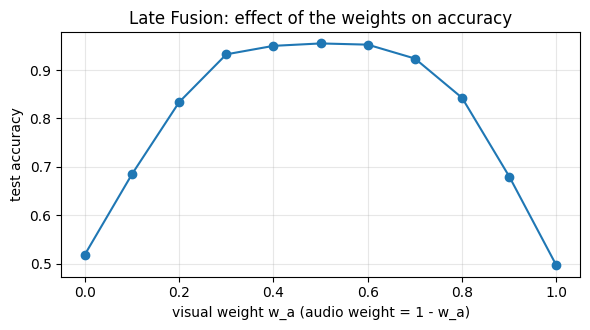

w_a     : [0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]
accuracy: [0.519 0.685 0.834 0.933 0.95  0.955 0.952 0.924 0.842 0.68  0.496]


In [56]:
# weight sweep: w for visual, 1 - w for audio
with torch.no_grad():
    p_a_te = torch.softmax(m_late.head_a(f_v_te), dim=1)
    p_b_te = torch.softmax(m_late.head_b(f_a_te), dim=1)

w_values = np.linspace(0, 1, 11)
acc_sweep = []
for w in w_values:
    pred = (float(w) * p_a_te + float(1 - w) * p_b_te).argmax(1)
    acc_sweep.append((pred == y_te).float().mean().item())

plt.figure(figsize=(6, 3.4))
plt.plot(w_values, acc_sweep, marker="o")
plt.xlabel("visual weight w_a (audio weight = 1 - w_a)")
plt.ylabel("test accuracy")
plt.title("Late Fusion: effect of the weights on accuracy")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("w_a     :", np.round(w_values, 1))
print("accuracy:", np.round(acc_sweep, 3))

## c. Jawab dalam 3-5 kalimat: mengapa strategi ini masih dapat melampaui baseline unimodal (~50%) meskipun encoder tidak boleh dilatih? Jelaskan peran rata-rata terbobot, lalu sebutkan satu kondisi di mana Late Fusion akan gagal.

In [57]:
y_xor = (label // 2) ^ (label % 2)           # 2 classes, balanced
yx_tr, yx_te = torch.tensor(y_xor[idx_train]), torch.tensor(y_xor[idx_test])

# unimodal models (2 classes)
torch.manual_seed(42)
xor_uv = nn.Linear(32, 2)
train(xor_uv, (f_v_tr,), yx_tr)

torch.manual_seed(42)
xor_ua = nn.Linear(32, 2)
train(xor_ua, (f_a_tr,), yx_tr)

# Late Fusion: two separate heads
torch.manual_seed(42)
xor_late = LateFusion(n_classes=2)
train(xor_late.head_a, (f_v_tr,), yx_tr)
train(xor_late.head_b, (f_a_tr,), yx_tr)

# Early Fusion
torch.manual_seed(42)
xor_early = EarlyFusion(n_classes=2)
train(xor_early, (v_tr, a_tr), yx_tr)

xor_results = pd.Series({
    "Visual only": (xor_uv(f_v_te).argmax(1) == yx_te).float().mean().item(),
    "Audio only": (xor_ua(f_a_te).argmax(1) == yx_te).float().mean().item(),
    "Late Fusion": evaluate(xor_late, v_te, a_te, yx_te),
    "Early Fusion": evaluate(xor_early, v_te, a_te, yx_te),
}, name="test accuracy (XOR label)").round(4)
display(xor_results.to_frame())

,test accuracy (XOR label)
Visual only,0.5288
Audio only,0.5113
Late Fusion,0.5288
Early Fusion,0.9375


Walaupun encoder dibekukan, tiap kepala tetap bisa belajar mengenali faktor dari modalitasnya sendiri, visual untuk valensi dan audio untuk gairah. Karena tebakan keduanya saling melengkapi, kalau skornya dirata-rata maka kelas yang benar jadi yang paling tinggi, sehingga akurasinya naik jauh di atas 50%.

Bobot menentukan seberapa besar pengaruh tiap modalitas, dan bobot yang seimbang memberi hasil terbaik karena keduanya sama-sama penting. Late Fusion akan gagal kalau label bergantung pada hubungan antar modalitas, misalnya XOR, karena tiap modalitas sendirian tidak memberi petunjuk apa pun (di percobaan XOR saya, Late Fusion hanya 0,529).

# Soal 4: Intermediate Fusion

## a. Tambahkan transformasi kecil per modalitas (lapisan tengah), lalu gabungkan hasilnya. Anda boleh memakai konkatenasi atau gating.

In [58]:
class IntermediateFusion(nn.Module):
    """Fusion at the middle layer, after a small per-modality transformation."""
    def __init__(self, dim_enc=32, dim_mid=32, n_classes=4):
        super().__init__()
        self.mid_a = nn.Sequential(nn.Linear(dim_enc, dim_mid), nn.Tanh())
        self.mid_b = nn.Sequential(nn.Linear(dim_enc, dim_mid), nn.Tanh())
        self.gate = nn.Sequential(nn.Linear(dim_mid * 2, dim_mid), nn.Sigmoid())
        self.head = nn.Sequential(
            nn.Linear(dim_mid, 64), nn.ReLU(),
            nn.Linear(64, n_classes),
        )

    def forward(self, x_visual, x_audio):
        with torch.no_grad():
            f_a = ENC_VISUAL(x_visual)
            f_b = ENC_AUDIO(x_audio)
        h_a, h_b = self.mid_a(f_a), self.mid_b(f_b)
        g = self.gate(torch.cat([h_a, h_b], dim=1))   # adaptive gate
        h = g * h_a + (1 - g) * h_b
        return self.head(h)

torch.manual_seed(42)
m_inter = IntermediateFusion()
train(m_inter, (v_tr, a_tr), y_tr)
acc_inter = evaluate(m_inter, v_te, a_te, y_te)
print(f"Intermediate Fusion (gating) accuracy: {acc_inter:.4f}")
print(f"(train accuracy: {evaluate(m_inter, v_tr, a_tr, y_tr):.4f})")

Intermediate Fusion (gating) accuracy: 0.9538
(train accuracy: 1.0000)


### Menggunakan konkatenasi atau Gating

In [59]:
class IntermediateConcat(nn.Module):
    """Comparison: same middle layers, but fused by concatenation (no gate)."""
    def __init__(self, dim_enc=32, dim_mid=32, n_classes=4):
        super().__init__()
        self.mid_a = nn.Sequential(nn.Linear(dim_enc, dim_mid), nn.Tanh())
        self.mid_b = nn.Sequential(nn.Linear(dim_enc, dim_mid), nn.Tanh())
        self.head = nn.Sequential(
            nn.Linear(dim_mid * 2, 64), nn.ReLU(),
            nn.Linear(64, n_classes),
        )

    def forward(self, x_visual, x_audio):
        with torch.no_grad():
            f_a = ENC_VISUAL(x_visual)
            f_b = ENC_AUDIO(x_audio)
        h = torch.cat([self.mid_a(f_a), self.mid_b(f_b)], dim=1)
        return self.head(h)

torch.manual_seed(42)
m_inter_cat = IntermediateConcat()
train(m_inter_cat, (v_tr, a_tr), y_tr)
acc_inter_cat = evaluate(m_inter_cat, v_te, a_te, y_te)
print(f"Intermediate Fusion (concatenation) accuracy: {acc_inter_cat:.4f}")

Intermediate Fusion (concatenation) accuracy: 0.9613


## b. Latih dan laporkan akurasinya.
## c. Bandingkan dengan Early dan Late Fusion. Anda akan melihat Intermediate sedikit di bawah Early karena encoder bersifat beku: lapisan tengah tambahan hanya menambah transformasi sebelum informasi dari kedua modalitas bertemu. Tuliskan analisis Anda dalam 4-6 kalimat, dan sebutkan bagaimana hasilnya akan berbeda bila encoder boleh ikut dilatih (fine-tuning).

In [60]:
fusion_compare = pd.DataFrame({
    "test accuracy": [acc_early, acc_late, acc_inter, acc_inter_cat],
}, index=["Early Fusion", "Late Fusion", "Intermediate (gating)", "Intermediate (concatenation, extra)"]).round(4)
fusion_compare["difference from Early"] = (fusion_compare["test accuracy"] - acc_early).round(4)
display(fusion_compare)

,test accuracy,difference from Early
Early Fusion,0.9613,0.0000
Late Fusion,0.9550,-0.0063
Intermediate (gating),0.9538,-0.0075
"Intermediate (concatenation, extra)",0.9613,0.0000


Intermediate Fusion mendapat 0,954, sedikit di bawah Early Fusion (0,961) dan hampir sama dengan Late Fusion (0,955). Penyebabnya encoder dibekukan: fitur yang masuk sudah tetap, jadi lapisan tengah hanya menambah satu transformasi sebelum visual dan audio bertemu, tanpa menambah informasi baru.

Selisihnya kecil, kurang dari satu persen, jadi bukan perbedaan yang besar. Kalau encoder boleh ikut dilatih (fine-tuning), lapisan tengah baru benar-benar berguna karena encoder bisa menyesuaikan fiturnya agar lebih mudah digabung. Dalam kondisi itu Intermediate Fusion bisa menyamai atau melampaui Early Fusion.

# Soal 5: Analisis Kritis dan Uji Modalitas Hilang

## a. Perbandingan dan Pemilihan
Sajikan akurasi ketiga strategi beserta baseline unimodal dalam satu tabel. Pilih satu strategi untuk sistem ini dan pertanggungjawabkan pilihan Anda berdasarkan akurasi, kompleksitas, dan kemudahan implementasi.

In [61]:
main_table = pd.DataFrame({
    "Test accuracy": [acc_uni_v, acc_uni_a, acc_early, acc_late, acc_inter],
    "Parameters (excluding encoders)": [sum(p.numel() for p in m.parameters())
                                        for m in (uni_visual, uni_audio, m_early, m_late, m_inter)],
}, index=["Visual only (baseline)", "Audio only (baseline)",
          "Early Fusion", "Late Fusion", "Intermediate Fusion (gating)"])
main_table["Test accuracy"] = main_table["Test accuracy"].round(4)
display(main_table)

,Test accuracy,Parameters (excluding encoders)
Visual only (baseline),0.4963,132
Audio only (baseline),0.5138,132
Early Fusion,0.9613,4420
Late Fusion,0.9550,266
Intermediate Fusion (gating),0.9538,6564


In [ ]:
# repeat the whole training with 5 different seeds (the data split stays the same)
results = []
for s in [42, 43, 44, 45, 46]:
    torch.manual_seed(s)
    uv = nn.Linear(32, 4)
    train(uv, (f_v_tr,), y_tr)

    torch.manual_seed(s)
    ua = nn.Linear(32, 4)
    train(ua, (f_a_tr,), y_tr)

    torch.manual_seed(s)
    me = EarlyFusion()
    train(me, (v_tr, a_tr), y_tr)

    torch.manual_seed(s)
    ml = LateFusion()
    train(ml.head_a, (f_v_tr,), y_tr)
    train(ml.head_b, (f_a_tr,), y_tr)

    torch.manual_seed(s)
    mi = IntermediateFusion()
    train(mi, (v_tr, a_tr), y_tr)

    zeros = torch.zeros_like(a_te)
    results.append({
        "Visual only": (uv(f_v_te).argmax(1) == y_te).float().mean().item(),
        "Audio only": (ua(f_a_te).argmax(1) == y_te).float().mean().item(),
        "Early": evaluate(me, v_te, a_te, y_te),
        "Late": evaluate(ml, v_te, a_te, y_te),
        "Intermediate": evaluate(mi, v_te, a_te, y_te),
        "Early (audio missing)": evaluate(me, v_te, zeros, y_te),
        "Late (audio missing)": evaluate(ml, v_te, zeros, y_te),
        "Intermediate (audio missing)": evaluate(mi, v_te, zeros, y_te),
    })

all_runs = pd.DataFrame(results, index=[42, 43, 44, 45, 46])
summary = pd.DataFrame({"mean": all_runs.mean(), "std": all_runs.std()}).round(4)
display(summary)

Grafik ringkasnya:

In [ ]:
names = ["Visual\nonly", "Audio\nonly", "Early", "Late", "Intermediate"]
values = [acc_uni_v, acc_uni_a, acc_early, acc_late, acc_inter]
colors = ["#999999", "#999999", "#4C72B0", "#55A868", "#C44E52"]

plt.figure(figsize=(7, 3.6))
bars = plt.bar(names, values, color=colors)
for b, v in zip(bars, values):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.03, f"{v:.3f}", ha="center", fontsize=9,
             bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
plt.axhline(0.5, color="black", linestyle=":", label="unimodal ceiling (50%)")
plt.axhline(0.95, color="red", linestyle="--", label="target 95%")
plt.ylim(0, 1.25)
plt.ylabel("test accuracy")
plt.title("Unimodal baselines vs the three fusion strategies")
plt.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

Dari tabel terlihat model unimodal hanya mencapai sekitar 50% (visual 0,496 dan audio 0,514), sedangkan ketiga strategi fusi naik ke sekitar 95%. Early Fusion paling tinggi (0,961), disusul Late (0,955) dan Intermediate (0,954), tetapi selisihnya kurang dari satu poin persen sehingga akurasi bukan pembeda yang kuat.

Dari sisi kompleksitas, Late Fusion paling ringan karena parameternya paling sedikit (266, dibanding 4.420 pada Early dan 6.564 pada Intermediate). Late Fusion juga paling mudah dibuat karena tiap kepalanya hanya satu lapisan linear yang dilatih terpisah, lalu skornya tinggal dirata-rata.

Karena itu saya memilih Late Fusion, walaupun untuk label seperti XOR saya akan beralih ke Early Fusion.

## b. Uji Modalitas Hilang
Ulangi pengujian dengan salah satu modalitas dinolkan (misalkan fitur audio diisi nol). Catat penurunan akurasi tiap strategi. Strategi mana yang paling tangguh, dan mengapa?

In [ ]:
# Zero out one modality -> measure how robust each strategy is
audio_zero = torch.zeros_like(a_te)

rows = []
for name, model in [("Early", m_early),
                    ("Late", m_late),
                    ("Intermediate", m_inter)]:
    acc_normal = evaluate(model, v_te, a_te, y_te)
    acc_missing = evaluate(model, v_te, audio_zero, y_te)
    print(f"{name:14s} normal={acc_normal:.3f} "
          f"audio-missing={acc_missing:.3f}")

    # which factor can still be guessed when the audio is missing?
    with torch.no_grad():
        pred = model(v_te, audio_zero).argmax(1)
    valence_correct = (pred // 2 == y_te // 2).float().mean().item()
    arousal_one = (pred % 2).float().mean().item()
    rows.append((name, acc_normal, acc_missing, valence_correct, arousal_one))

missing_table = pd.DataFrame(rows, columns=["Strategy", "normal", "audio missing",
                                            "valence still correct", "predicted arousal=1"]).set_index("Strategy")
missing_table["drop"] = missing_table["normal"] - missing_table["audio missing"]
missing_table["gap from visual baseline"] = missing_table["audio missing"] - acc_uni_v
missing_table = missing_table[["normal", "audio missing", "drop", "gap from visual baseline",
                               "valence still correct", "predicted arousal=1"]]
display(missing_table.round(3))
print(f"True share of arousal=1 in the test data: {(y_te % 2).float().mean().item():.3f}")

# extra: what if the visual modality is the one that goes missing?
visual_zero = torch.zeros_like(v_te)
print("\nExtra, visual zeroed:")
for name, model in [("Early", m_early), ("Late", m_late), ("Intermediate", m_inter)]:
    print(f"{name:14s} visual-missing={evaluate(model, visual_zero, a_te, y_te):.3f}")

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(3)
ax.bar(x - 0.18, missing_table["normal"], width=0.36, label="normal", color="#4C72B0")
ax.bar(x + 0.18, missing_table["audio missing"], width=0.36, label="audio missing", color="#DD8452")
ax.set_xticks(x)
ax.set_xticklabels(missing_table.index)
ax.axhline(0.5, color="black", linestyle=":")
ax.set_ylim(0, 1.25)
ax.set_ylabel("test accuracy")
ax.set_title("Robustness when the audio modality is missing")
ax.legend(loc="upper right", ncol=2)
plt.tight_layout()
plt.show()

# why does Late Fusion stay "calm"? look at the audio head's scores for a zero input
with torch.no_grad():
    p_b_zero = torch.softmax(m_late.head_b(ENC_AUDIO(audio_zero[:1])), dim=1)[0]
print("Audio head scores for a zero input:", p_b_zero.numpy().round(3), "(almost uniform, about 0.25 per class)")

Saat audio dinolkan, ketiga strategi jatuh ke sekitar 50%: Early dari 0,961 menjadi 0,512, Late dari 0,955 menjadi 0,499, dan Intermediate dari 0,954 menjadi 0,477.

Ini wajar karena gairah hanya ada di audio, jadi tanpa audio model tinggal menebak separuh jawaban sisanya, sehingga akurasinya sama dengan baseline visual. Selisih antar strategi yang kecil (0,477 sampai 0,512) bukan tanda ketangguhan, karena itu hanya hasil tebakan gairah yang kebetulan condong ke satu sisi.

Meski begitu, Late Fusion yang paling tangguh walaupun keunggulannya tipis, karena hasilnya jatuh tepat ke baseline visual (0,499 dibanding 0,496).

Penyebabnya, kepala visual pada Late Fusion dilatih sendiri dan tidak bergantung pada audio, sedangkan kepala audio yang menerima nol hanya mengeluarkan skor hampir seragam sehingga tidak mengganggu keputusan visual.

Pada Early dan Intermediate, nol di bagian audio adalah masukan yang belum pernah dilihat saat latihan, jadi keputusannya tidak menentu.

# c. Kaitan dengan Teori
Hubungkan hasil Anda dengan dua gagasan dari perkuliahan: (i) masalah redundansi, konflik, dan dominasi modalitas; serta (ii) peringatan bahwa penambahan modalitas tidak otomatis meningkatkan kinerja. Apakah data sintetis pada tugas ini termasuk kasus yang menguntungkan bagi fusi? Jelaskan.

Masalah klasik fusi ada tiga: redundansi (dua modalitas membawa informasi yang sama), konflik (dua modalitas saling bertentangan), dan dominasi (satu modalitas menenggelamkan yang lain).

Pada data sintetis ini ketiganya hampir tidak muncul: visual dan audio membawa faktor yang berbeda, label memang gabungan keduanya, dan keduanya sama-sama informatif (masing-masing sekitar 50% kalau sendirian).

Karena itu menambah modalitas di sini sangat membantu, akurasi naik dari sekitar 50% ke sekitar 95%.

Namun menambah modalitas tidak otomatis meningkatkan kinerja, sebab kalau modalitas tambahan hanya berisi suara berisik atau bertentangan dengan yang lain, akurasi bisa tidak naik atau malah turun.

Jadi data sintetis ini termasuk kasus yang sangat menguntungkan bagi fusi, karena kedua modalitasnya saling melengkapi dan tidak saling bertentangan. Pada data nyata hal itu belum tentu berlaku, jadi strategi fusinya perlu diuji dulu.